<a href="https://colab.research.google.com/github/Shreyasbmys/DSSS_Ex2_131023/blob/main/FAUlogo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%pip install phiflow
from phi.jax.flow import *
# from phi.flow import *  # If JAX is not installed. You can use phi.torch or phi.tf as well.

In [4]:
domain = dict(x=128, y=128, bounds=Box(x=100, y=100))
# Create geometry for "FAU" letters
# Letter F
f_vertical = Box['x,y', 15:20, 41:83]
f_top = Box['x,y', 15:35, 78:83]
f_middle = Box['x,y', 15:30, 60:65]

# Letter A
a_left = Box['x,y', 40:45, 41:83]
a_right = Box['x,y', 55:60, 41:83]
a_top = Box['x,y', 40:60, 78:83]
a_middle = Box['x,y', 40:60, 60:65]

# Letter U
u_left = Box['x,y', 65:70, 41:83]
u_right = Box['x,y', 80:85, 41:83]
u_bottom = Box['x,y', 65:85, 41:46]

geometries = [f_vertical, f_top, f_middle, a_left, a_right, a_top, a_middle, u_left, u_right, u_bottom]
geometry = union(geometries)

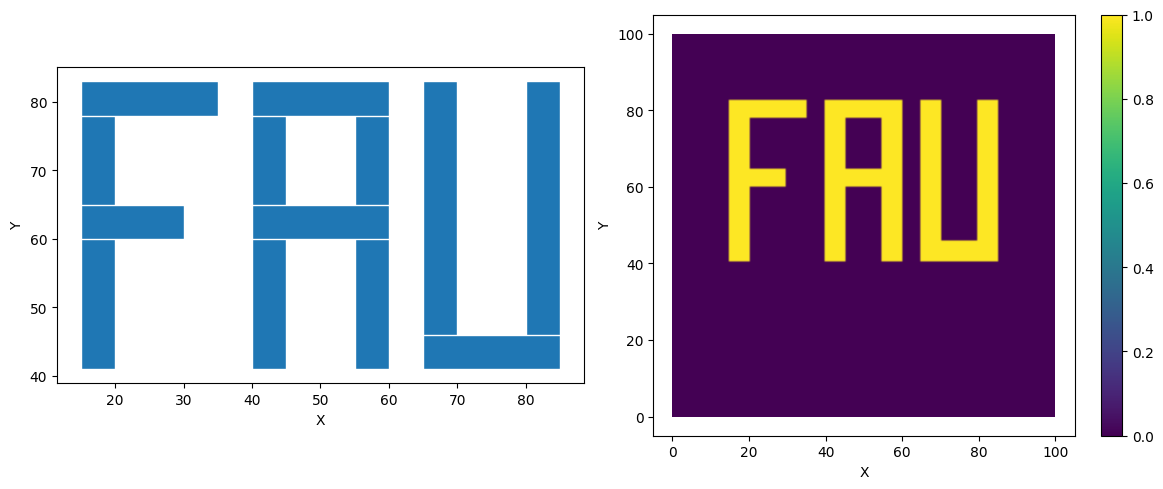

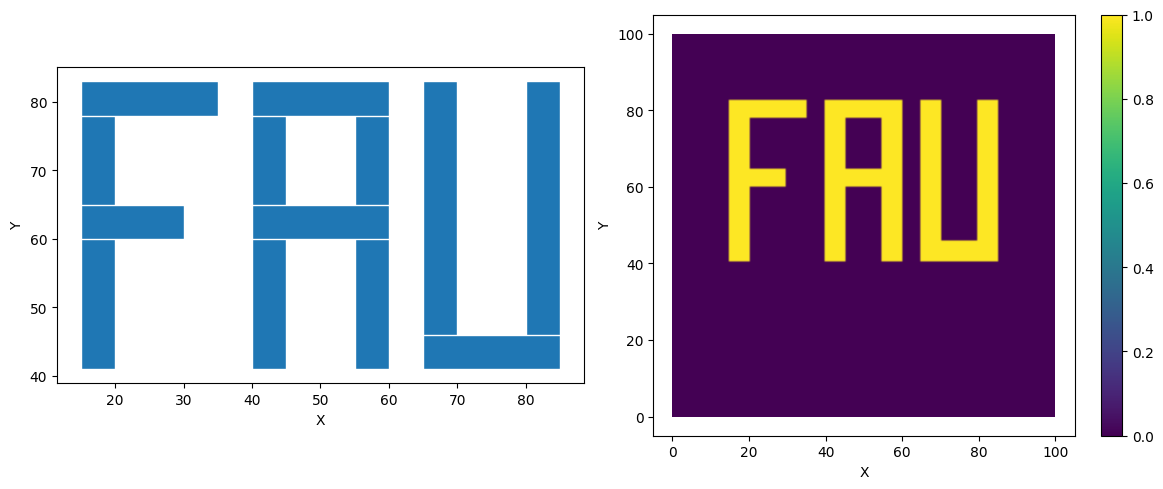

In [5]:
plot(geometry, CenteredGrid(geometry, 0, **domain))

/usr/local/lib/python3.11/dist-packages/phi/vis/_matplotlib/_matplotlib_plots.py:167: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()  # because subplot titles can be added after figure creation


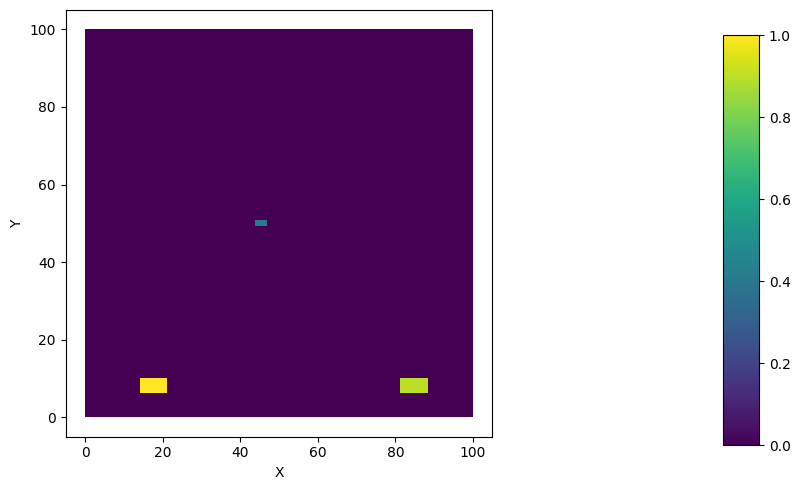

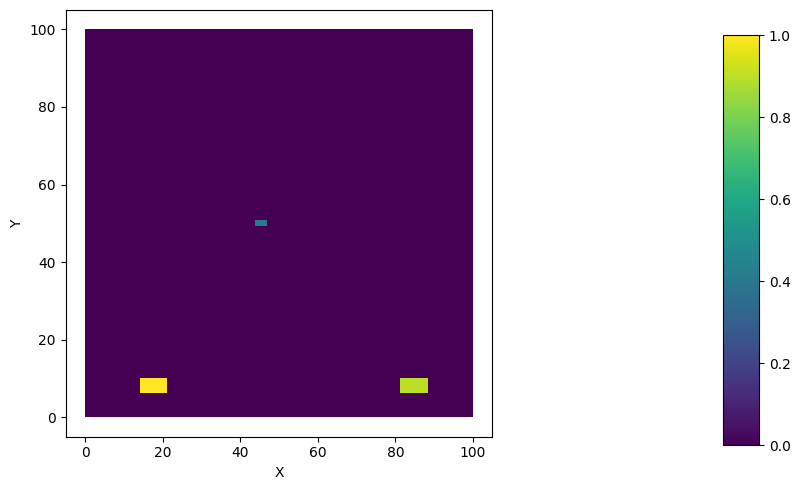

In [6]:
inflow = CenteredGrid(Box(x=(14, 21), y=(6, 10)), ZERO_GRADIENT, **domain) + \
         CenteredGrid(Box(x=(81, 88), y=(6, 10)), ZERO_GRADIENT, **domain) * 0.9 + \
         CenteredGrid(Box(x=(44, 47), y=(49, 51)), ZERO_GRADIENT, **domain) * 0.4
plot(inflow)

In [7]:
@jit_compile
def step(smoke, v, pressure, inflow, dt=1.):
    smoke = advect.semi_lagrangian(smoke, v, 1) + inflow
    buoyancy_force = resample(smoke * (0, 0.1), to=v)
    v = advect.semi_lagrangian(v, v, 1) + buoyancy_force
    v, pressure = fluid.make_incompressible(v, geometry, Solve('CG-adaptive', 1e-5, x0=pressure))
    return smoke, v, pressure

v0 = StaggeredGrid(0, boundary=0, **domain)
smoke0 = CenteredGrid(0, boundary=ZERO_GRADIENT, **domain)
smoke_trj, v_trj, pressure_trj = iterate(step, batch(time=200), smoke0, v0, None, inflow=inflow)

KeyboardInterrupt: 

In [ ]:
# Simple animation without color specification
plot(smoke_trj, animate='time')

# Alternative: Plot a single frame to see the result
plot(smoke_trj.time[50])  # Plot frame 50

# Alternative: Save animation to file using matplotlib directly
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# Create animation manually to save as file
fig, ax = plt.subplots()
def animate_frame(frame):
    ax.clear()
    # Extract single frame and plot it
    frame_data = smoke_trj.time[frame]
    # Use PhiFlow's plot but capture the matplotlib figure
    plot(frame_data)

# Create animation
ani = animation.FuncAnimation(fig, animate_frame, frames=range(0, 200, 5), interval=100)
ani.save('fau_fluid_animation.gif', writer='pillow', fps=10)
plt.close()

# Or simply use the basic plot for inline display
plot(smoke_trj, animate='time')